# SilverAI - Notebook 08: Model Evaluation

Evaluate validation-selected models on the untouched chronological test partition. No retraining, tuning, or test-based selection is performed.

In [1]:
from pathlib import Path
import json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score, mean_absolute_error, mean_squared_error, r2_score
PROJECT_ROOT=Path.cwd()
if not (PROJECT_ROOT/'data').exists(): PROJECT_ROOT=Path('..').resolve()
INPUT_PATH=PROJECT_ROOT/'data'/'silver_modeling_data.csv'; MODEL_ROOT=PROJECT_ROOT/'saved_models'
REPORT_ROOT=PROJECT_ROOT/'reports'/'model_comparison'; REPORT_ROOT.mkdir(parents=True,exist_ok=True)
FIGURE_ROOT=PROJECT_ROOT/'reports'/'figures'; FIGURE_ROOT.mkdir(parents=True,exist_ok=True)
FEATURE_COLUMNS=['return_1','return_3','return_6','volatility_5','volatility_20','volatility_50','sma_distance_20','sma_distance_50','candle_return','candle_range_pct','upper_wick_ratio','lower_wick_ratio','relative_volume','volume_change','hour_sin','hour_cos','day_of_week']
REGRESSION_TARGET='future_return_15m'; SAVED_CLASSIFICATION_TARGET='target_direction_15m'; CLASSIFIER_NAME='hist_gradient_boosting_classifier'; REGRESSOR_NAME='linear_regression'; PURGE_ROWS=3

In [2]:
df=pd.read_csv(INPUT_PATH); df['_sort']=pd.to_datetime(df.datetime_et,errors='coerce',utc=True); df=df.sort_values('_sort',kind='mergesort').reset_index(drop=True)
numeric=FEATURE_COLUMNS+[REGRESSION_TARGET]; invalid=df[FEATURE_COLUMNS].isna().any(axis=1)|df[[REGRESSION_TARGET,SAVED_CLASSIFICATION_TARGET]].isna().any(axis=1)|np.isinf(df[numeric].to_numpy(float)).any(axis=1); clean_df=df.loc[~invalid].reset_index(drop=True).copy()
metadata=json.loads((MODEL_ROOT/'metadata'/'training_metadata.json').read_text(encoding='utf-8')); assert metadata['feature_names']==FEATURE_COLUMNS; assert metadata['prediction_horizon_minutes']==15 and metadata['prediction_horizon_bars']==3
threshold_pct=float(metadata['threshold_value_pct']); classifier=joblib.load(MODEL_ROOT/'classifier'/f'{CLASSIFIER_NAME}.joblib'); regressor=joblib.load(MODEL_ROOT/'regressor'/f'{REGRESSOR_NAME}.joblib')
n=len(clean_df); b70=int(n*.70); b85=int(n*.85); train_raw=clean_df.iloc[:b70].copy(); validation_raw=clean_df.iloc[b70:b85].copy(); test=clean_df.iloc[b85:].copy(); train=train_raw.iloc[:-PURGE_ROWS].copy(); validation=validation_raw.iloc[:-PURGE_ROWS].copy()
assert (len(train),train.datetime_et.iloc[0],train.datetime_et.iloc[-1])==(len(train),metadata['training_start'],metadata['training_end']); assert (len(validation),validation.datetime_et.iloc[0],validation.datetime_et.iloc[-1])==(len(validation),metadata['validation_start'],metadata['validation_end'])
def make_labels(s): return pd.Series(np.where(s>threshold_pct,1,np.where(s<-threshold_pct,-1,0)),index=s.index,dtype='int64')
for part in (train,validation,test): part['eval_direction']=make_labels(part[REGRESSION_TARGET])
X_train,X_val,X_test=train[FEATURE_COLUMNS],validation[FEATURE_COLUMNS],test[FEATURE_COLUMNS]; y_train,y_val,y_test=train.eval_direction,validation.eval_direction,test.eval_direction; r_train,r_val,r_test=train[REGRESSION_TARGET],validation[REGRESSION_TARGET],test[REGRESSION_TARGET]
print(f'Input rows={len(df):,}; removed={int(invalid.sum()):,}; clean={len(clean_df):,}; test={len(test):,}')

Input rows=160,612; removed=39; clean=160,573; test=24,086


C:\Users\ravik\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.7.2 when using version 1.7.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\ravik\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator _BinMapper from version 1.7.2 when using version 1.7.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\ravik\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator His

In [3]:
val_cls_pred=classifier.predict(X_val); test_cls_pred=classifier.predict(X_test); majority=np.full(len(y_test),int(y_train.mode().iloc[0]))
def cls_metrics(y,p,name): return {'model':name,'accuracy':accuracy_score(y,p),'balanced_accuracy':balanced_accuracy_score(y,p),'macro_f1':f1_score(y,p,average='macro')}
test_classification_metrics=pd.DataFrame([cls_metrics(y_test,majority,'majority_class_baseline'),cls_metrics(y_test,test_cls_pred,CLASSIFIER_NAME)]); test_classification_metrics.to_csv(REPORT_ROOT/'test_classification_metrics.csv',index=False)
test_classification_report=pd.DataFrame(classification_report(y_test,test_cls_pred,labels=[-1,0,1],target_names=['DOWN','NEUTRAL','UP'],output_dict=True,zero_division=0)).T; test_classification_report.to_csv(REPORT_ROOT/'test_classification_report.csv')
test_confusion=pd.DataFrame(confusion_matrix(y_test,test_cls_pred,labels=[-1,0,1]),index=['actual_DOWN','actual_NEUTRAL','actual_UP'],columns=['pred_DOWN','pred_NEUTRAL','pred_UP']); test_confusion.to_csv(REPORT_ROOT/'test_confusion_matrix.csv'); display(test_classification_metrics.round(4)); display(test_classification_report.round(4)); display(test_confusion)

C:\Users\ravik\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\ravik\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\ravik\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\ravik\AppData\Local\Programs\Python\Pytho

,model,accuracy,balanced_accuracy,macro_f1
0,majority_class_baseline,0.2700,0.3333,0.1417
1,hist_gradient_boosting_classifier,0.3837,0.3857,0.3731


,precision,recall,f1-score,support
DOWN,0.4148,0.2368,0.3015,9060.0000
NEUTRAL,0.3699,0.3687,0.3693,6504.0000
UP,0.3780,0.5515,0.4486,8522.0000
accuracy,0.3837,0.3837,0.3837,0.3837
macro avg,0.3876,0.3857,0.3731,24086.0000
weighted avg,0.3897,0.3837,0.3718,24086.0000


,pred_DOWN,pred_NEUTRAL,pred_UP
actual_DOWN,2145,2162,4753
actual_NEUTRAL,1126,2398,2980
actual_UP,1900,1922,4700


In [4]:
val_reg_pred=regressor.predict(X_val); test_reg_pred=regressor.predict(X_test); zero=np.zeros(len(r_test))
test_regression_metrics=pd.DataFrame([{'model':'zero_return_baseline','mae':mean_absolute_error(r_test,zero),'rmse':mean_squared_error(r_test,zero)**.5,'r2':r2_score(r_test,zero)},{'model':REGRESSOR_NAME,'mae':mean_absolute_error(r_test,test_reg_pred),'rmse':mean_squared_error(r_test,test_reg_pred)**.5,'r2':r2_score(r_test,test_reg_pred)}]); test_regression_metrics.to_csv(REPORT_ROOT/'test_regression_metrics.csv',index=False)
test_predictions=pd.DataFrame({'datetime_et':test.datetime_et.to_numpy(),'actual_future_return_15m':r_test.to_numpy(),'predicted_future_return_15m':test_reg_pred,'volatility_20':test.volatility_20.to_numpy(),'relative_volume':test.relative_volume.to_numpy()}); test_predictions['residual']=test_predictions.actual_future_return_15m-test_predictions.predicted_future_return_15m; test_predictions.to_csv(REPORT_ROOT/'test_regression_predictions.csv',index=False); display(test_regression_metrics.round(6))

,model,mae,rmse,r2
0,zero_return_baseline,0.220179,0.319404,-0.000103
1,linear_regression,0.220403,0.319522,-0.000840


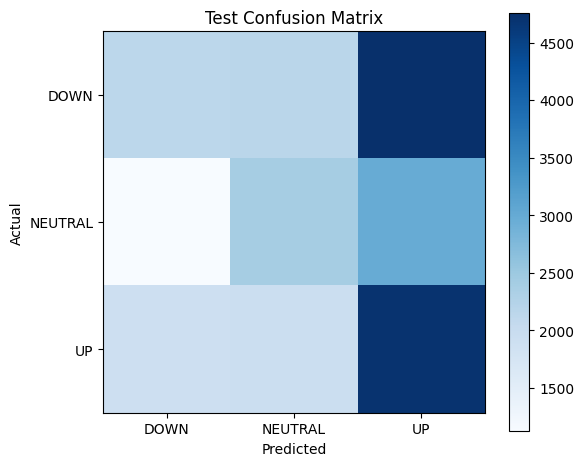

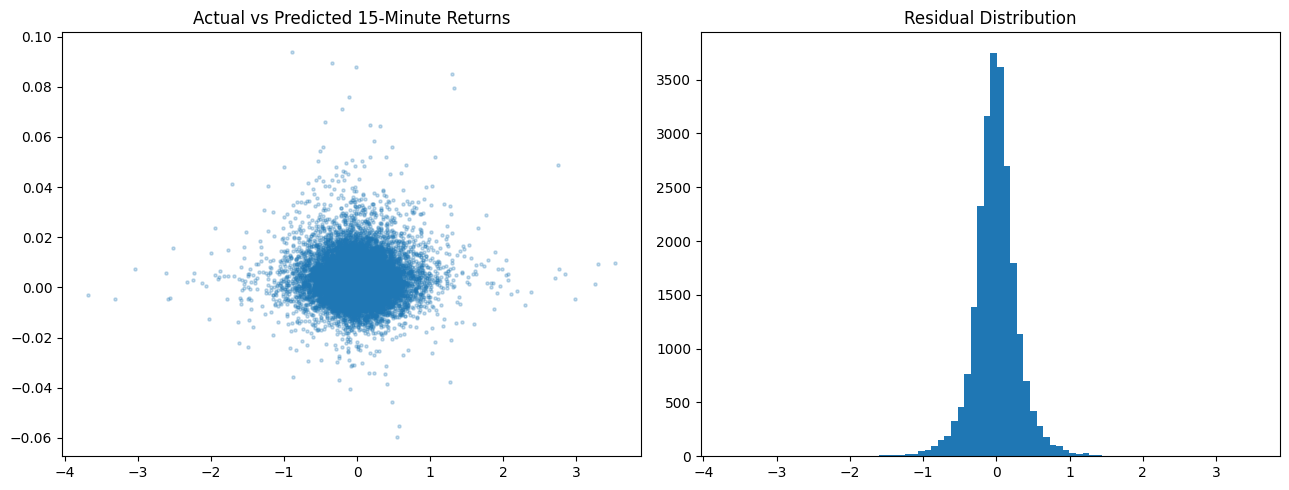

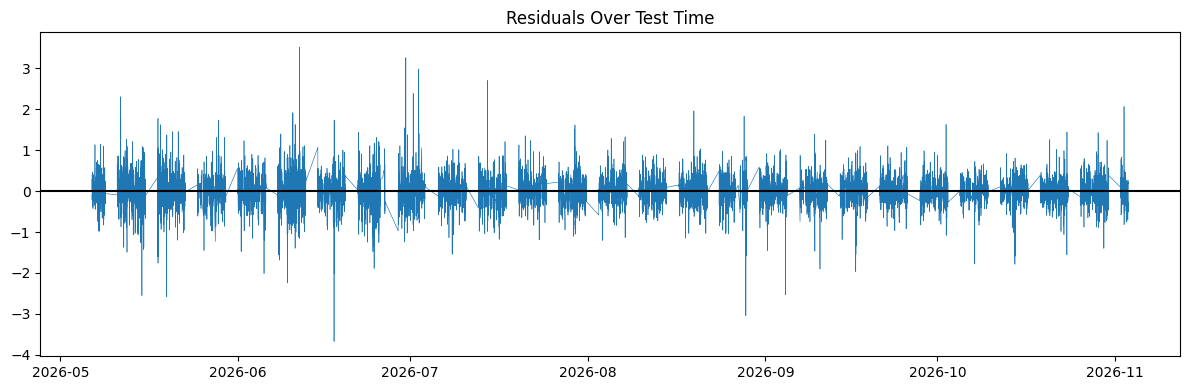

In [5]:
fig,ax=plt.subplots(figsize=(6,5)); im=ax.imshow(test_confusion.values,cmap='Blues'); ax.set_xticks(range(3),['DOWN','NEUTRAL','UP']); ax.set_yticks(range(3),['DOWN','NEUTRAL','UP']); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Test Confusion Matrix'); fig.colorbar(im,ax=ax); fig.tight_layout(); fig.savefig(FIGURE_ROOT/'11_test_confusion_matrix.png',dpi=160); plt.show()
fig,axes=plt.subplots(1,2,figsize=(13,5)); axes[0].scatter(test_predictions.actual_future_return_15m,test_predictions.predicted_future_return_15m,s=5,alpha=.25); axes[0].set_title('Actual vs Predicted 15-Minute Returns'); axes[1].hist(test_predictions.residual,bins=80); axes[1].set_title('Residual Distribution'); fig.tight_layout(); fig.savefig(FIGURE_ROOT/'12_actual_vs_predicted_and_residuals.png',dpi=160); plt.show()
plt.figure(figsize=(12,4)); plt.plot(pd.to_datetime(test_predictions.datetime_et,utc=True),test_predictions.residual,linewidth=.45); plt.axhline(0,color='black'); plt.title('Residuals Over Test Time'); plt.tight_layout(); plt.savefig(FIGURE_ROOT/'13_residuals_over_time.png',dpi=160); plt.show()

In [6]:
condition=test_predictions.copy(); condition['volatility_condition']=pd.qcut(condition.volatility_20,3,labels=['low_volatility','medium_volatility','high_volatility'],duplicates='drop'); condition['volume_condition']=pd.qcut(condition.relative_volume,3,labels=['low_relative_volume','medium_relative_volume','high_relative_volume'],duplicates='drop')
def error_summary(g): return pd.Series({'rows':len(g),'mae':mean_absolute_error(g.actual_future_return_15m,g.predicted_future_return_15m),'rmse':mean_squared_error(g.actual_future_return_15m,g.predicted_future_return_15m)**.5})
volatility_summary=condition.groupby('volatility_condition',observed=True).apply(error_summary).reset_index(); volume_summary=condition.groupby('volume_condition',observed=True).apply(error_summary).reset_index(); volatility_summary.to_csv(REPORT_ROOT/'regression_error_by_volatility.csv',index=False); volume_summary.to_csv(REPORT_ROOT/'regression_error_by_volume.csv',index=False); display(volatility_summary.round(6)); display(volume_summary.round(6))

C:\Users\ravik\AppData\Local\Temp\ipykernel_27596\604231350.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  volatility_summary=condition.groupby('volatility_condition',observed=True).apply(error_summary).reset_index(); volume_summary=condition.groupby('volume_condition',observed=True).apply(error_summary).reset_index(); volatility_summary.to_csv(REPORT_ROOT/'regression_error_by_volatility.csv',index=False); volume_summary.to_csv(REPORT_ROOT/'regression_error_by_volume.csv',index=False); display(volatility_summary.round(6)); display(volume_summary.round(6))
C:\Users\ravik\AppData\Local\Temp\ipykernel_27596\604231350.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This 

,volatility_condition,rows,mae,rmse
0,low_volatility,8029.0,0.165871,0.238537
1,medium_volatility,8028.0,0.208524,0.293648
2,high_volatility,8029.0,0.286813,0.403921


,volume_condition,rows,mae,rmse
0,low_relative_volume,8029.0,0.190025,0.264493
1,medium_relative_volume,8028.0,0.215883,0.312411
2,high_relative_volume,8029.0,0.255302,0.372458


In [7]:
generalization=pd.DataFrame([{'partition':'train','classification_accuracy':accuracy_score(y_train,classifier.predict(X_train)),'classification_macro_f1':f1_score(y_train,classifier.predict(X_train),average='macro'),'regression_mae':mean_absolute_error(r_train,regressor.predict(X_train)),'regression_rmse':mean_squared_error(r_train,regressor.predict(X_train))**.5},{'partition':'validation','classification_accuracy':accuracy_score(y_val,val_cls_pred),'classification_macro_f1':f1_score(y_val,val_cls_pred,average='macro'),'regression_mae':mean_absolute_error(r_val,val_reg_pred),'regression_rmse':mean_squared_error(r_val,val_reg_pred)**.5},{'partition':'test','classification_accuracy':accuracy_score(y_test,test_cls_pred),'classification_macro_f1':f1_score(y_test,test_cls_pred,average='macro'),'regression_mae':mean_absolute_error(r_test,test_reg_pred),'regression_rmse':mean_squared_error(r_test,test_reg_pred)**.5}]); generalization.to_csv(REPORT_ROOT/'generalization_comparison.csv',index=False); display(generalization.round(6))
manifest={'selected_classifier':CLASSIFIER_NAME,'selected_regressor':REGRESSOR_NAME,'selection_basis':'Notebook 07 validation performance; test results not used for selection','threshold_pct':threshold_pct,'test_rows':len(test)}; (REPORT_ROOT/'evaluation_selection.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8'); print('Saved outputs to',REPORT_ROOT)

,partition,classification_accuracy,classification_macro_f1,regression_mae,regression_rmse
0,train,0.499555,0.447280,0.144225,0.212145
1,validation,0.422912,0.388928,0.357133,0.576681
2,test,0.383750,0.373119,0.220403,0.319522


Saved outputs to C:\Users\ravik\Desktop\SilverAI\reports\model_comparison
